# Task 2 – Metric Learning with Triplet Loss

Train the embedding network with the balanced batch sampler and triplet loss.

## Context
Task 2 focuses on metric learning so that the system can recognise both existing and emerging styles. The goal is to train the same backbone with a triplet loss so that images of the same article type lie close together in the feature space while images of different types are pushed apart. The learned embeddings will later support the recommendation system and the qualitative analyses from Task 3 and Task 4. This notebook therefore covers the training procedure, the triplet mining strategy, and the validation metrics.

In [1]:
from pathlib import Path

import torch
from torch.utils.data import DataLoader

from fashion_metric import (
    CNET_HHD0_V44,
    BalancedBatchSampler,
    TripletLoss,
    InformativeNegativeTripletSelector,
    Trainer,
)
from fashion_metric.data import build_all_datasets

In [2]:
DATASETS = build_all_datasets()
train_dataset = DATASETS["train_dataset"]
main_test_dataset = DATASETS["main_test_dataset"]

In [3]:
N_CLASSES_PER_BATCH = 10
N_SAMPLES_PER_CLASS = 25
MARGIN = 0.2
EPOCHS = 70
LEARNING_RATE = 0.1
MOMENTUM = 0.8
BATCH_SIZE = N_CLASSES_PER_BATCH * N_SAMPLES_PER_CLASS

In [4]:
train_sampler = BalancedBatchSampler(train_dataset.targets, n_classes=N_CLASSES_PER_BATCH, n_samples=N_SAMPLES_PER_CLASS)
val_sampler = BalancedBatchSampler(main_test_dataset.targets, n_classes=N_CLASSES_PER_BATCH, n_samples=N_SAMPLES_PER_CLASS)

triplets_train_loader = DataLoader(train_dataset, batch_sampler=train_sampler)
triplets_val_loader = DataLoader(main_test_dataset, batch_sampler=val_sampler)


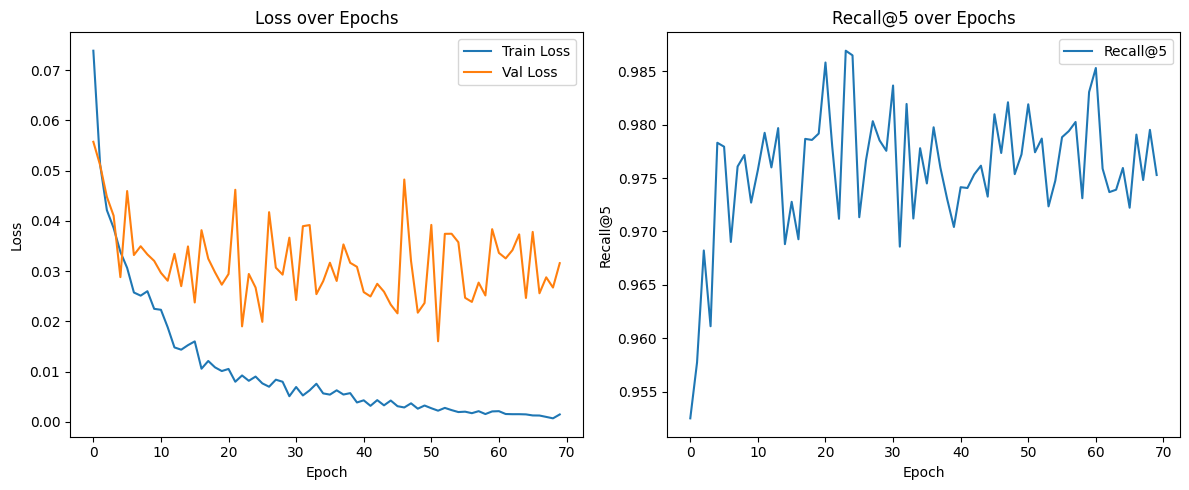

100%|██████████| 70/70 [1:22:07<00:00, 70.40s/it]


📦 Saved final model as last_model.pt
Saved metric model to output/metric_learning/metric_model.pt


In [5]:
ENABLE_TRAINING = True
OUTPUT_DIR = Path("output/metric_learning")

if ENABLE_TRAINING:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = CNET_HHD0_V44(num_classes=39, input_shape=(3, 60, 80)).to(device)
    criterion = TripletLoss(MARGIN, InformativeNegativeTripletSelector(MARGIN))
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)

    trainer = Trainer(
        model=model,
        device=device,
        criterion=criterion,
        optimizer=optimizer,
        training_DataLoader=triplets_train_loader,
        validation_DataLoader=triplets_val_loader,
        epochs=EPOCHS,
    )
    trainer.run_trainer()

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    saved_model = Path("last_model.pt")
    if saved_model.exists():
        target_path = OUTPUT_DIR / "metric_model.pt"
        saved_model.replace(target_path)
        print(f"Saved metric model to {target_path}")
else:
    print("Training is disabled. Set ENABLE_TRAINING = True to run the Task 2 experiment.")